
## Install Dependencies


In [1]:
import subprocess, sys
subprocess.run([
    sys.executable, '-m', 'pip', 'install',
    'torch', 'torchvision', '--index-url',
    'https://download.pytorch.org/whl/cu121',  # CUDA 12.1 — matches RTX 4050 driver
    '--quiet'
], check=True)
subprocess.run([
    sys.executable, '-m', 'pip', 'install', '--quiet',
    'transformers', 'albumentations', 'optuna', 'timm',
    'evaluate', 'accelerate', 'scikit-learn', 'seaborn',
    'opencv-python', 'matplotlib', 'numpy'
], check=True)
print('All packages installed.')

All packages installed.


## Defining Data Paths

In [2]:
import os

IMAGE_DIR = r'E:\Workplaces\CSE465 Project\RRSIS-D\JPEGImages'
LABEL_DIR = r'E:\Workplaces\CSE465 Project\RRSIS-D\ann_split'

# Base folder for all training runs
RUNS_BASE = r'E:\Workplaces\CSE465 Project\runs'

os.makedirs(RUNS_BASE, exist_ok=True)

print('Image  dir:', IMAGE_DIR)
print('Label  dir:', LABEL_DIR)
print('Runs   dir:', RUNS_BASE)
print('Image dir exists?', os.path.exists(IMAGE_DIR))
print('Label dir exists?', os.path.exists(LABEL_DIR))

Image  dir: E:\Workplaces\CSE465 Project\RRSIS-D\JPEGImages
Label  dir: E:\Workplaces\CSE465 Project\RRSIS-D\ann_split
Runs   dir: E:\Workplaces\CSE465 Project\runs
Image dir exists? True
Label dir exists? True


## Create Timestamped Run Folder

In [3]:
from datetime import datetime

RUN_NAME   = f'run_{datetime.now().strftime("%Y%m%d_%H%M%S")}'
OUTPUT_DIR = os.path.join(RUNS_BASE, RUN_NAME)

# Sub-directories
WEIGHTS_DIR = os.path.join(OUTPUT_DIR, 'weights')
PLOTS_DIR   = os.path.join(OUTPUT_DIR, 'plots')
LOGS_DIR    = os.path.join(OUTPUT_DIR, 'logs')
CACHE_DIR   = os.path.join(OUTPUT_DIR, 'cache')

for d in [WEIGHTS_DIR, PLOTS_DIR, LOGS_DIR, CACHE_DIR]:
    os.makedirs(d, exist_ok=True)

# Checkpoint paths
BEST_CKPT_PATH = os.path.join(WEIGHTS_DIR, 'best_model.pt')
LAST_CKPT_PATH = os.path.join(WEIGHTS_DIR, 'last_model.pt')
LOG_FILE       = os.path.join(LOGS_DIR, 'train_log.txt')
SUMMARY_FILE   = os.path.join(LOGS_DIR, 'results_summary.json')
OPTUNA_FILE    = os.path.join(LOGS_DIR, 'optuna_study.pkl')

# Also write run info to the cache dir for the sampler
SAMPLER_CACHE  = os.path.join(CACHE_DIR, 'train_dominant_classes.npy')

print(f'Run folder: {OUTPUT_DIR}')

Run folder: E:\Workplaces\CSE465 Project\runs\run_20260411_002521


## Imports & GPU Configuration

In [4]:
import glob, json, random, time, xml.etree.ElementTree as ET
import pickle
from pathlib import Path
from collections import Counter

import numpy as np
import cv2
from PIL import Image
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import GradScaler, autocast

import albumentations as A
from albumentations.pytorch import ToTensorV2

from transformers import logging as hf_logging
hf_logging.set_verbosity_error()

from transformers import (
    SegformerForSemanticSegmentation,
    SegformerImageProcessor,
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# GPU optimisations for RTX 4050
torch.backends.cudnn.benchmark      = True
torch.backends.cudnn.deterministic   = False
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32       = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f'GPU    : {props.name}')
    print(f'VRAM   : {props.total_memory / 1e9:.1f} GB')
    print(f'CUDA   : {torch.version.cuda}')
    print(f'cuDNN  : {torch.backends.cudnn.version()}')
    print(f'TF32   : enabled')


Device : cuda
GPU    : NVIDIA GeForce RTX 4050 Laptop GPU
VRAM   : 6.4 GB
CUDA   : 11.8
cuDNN  : 90100
TF32   : enabled


## Logging Utility

In [5]:
import sys

_real_stdout = sys.stdout

def save_to_log(text):
    """Append a string directly to the log file."""
    with open(LOG_FILE, 'a', encoding='utf-8') as f:
        f.write(text)
        f.write('\n')

save_to_log(f'Run started: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
save_to_log(f'Run folder : {OUTPUT_DIR}')

print(f'Run started: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
print(f'Run folder : {OUTPUT_DIR}')
print(f'Log file   : {LOG_FILE}')

Run started: 2026-04-11 00:26:47
Run folder : E:\Workplaces\CSE465 Project\runs\run_20260411_002521
Log file   : E:\Workplaces\CSE465 Project\runs\run_20260411_002521\logs\train_log.txt


## Parse Classes from XML (Imbalance Check)

In [6]:
images_path = Path(IMAGE_DIR)
labels_path = Path(LABEL_DIR)

xml_files = list(labels_path.rglob('*.xml'))
print(f'Total XML files: {len(xml_files)}')

class_names_set = set()
box_counts      = Counter()

for xf in xml_files:
    tree = ET.parse(xf)
    root = tree.getroot()
    for obj in root.findall('object'):
        name = obj.find('name').text.strip()
        class_names_set.add(name)
        box_counts[name] += 1

Total XML files: 17402


## Convert to Ordered Class List

In [7]:
class_names = sorted(list(class_names_set))
num_classes = len(class_names)

# Map class name → ID
class_to_id = {name: i for i, name in enumerate(class_names)}

print("Number of classes:", num_classes)
print("All classes:", class_names[:])

## Convert Counts to Array
counts = np.zeros(num_classes, dtype=int)

for class_name, count in box_counts.items():
    class_id = class_to_id[class_name]
    counts[class_id] = count

Number of classes: 20
All classes: ['Expressway-Service-area', 'Expressway-toll-station', 'airplane', 'airport', 'baseballfield', 'basketballcourt', 'bridge', 'chimney', 'dam', 'golffield', 'groundtrackfield', 'harbor', 'overpass', 'ship', 'stadium', 'storagetank', 'tenniscourt', 'trainstation', 'vehicle', 'windmill']


## Imbalance Metrics

In [8]:
total_boxes     = counts.sum()
nonzero         = counts[counts > 0]
max_boxes       = int(nonzero.max()) if len(nonzero) else 0
min_boxes       = int(nonzero.min()) if len(nonzero) else 0
imbalance_ratio = (max_boxes / min_boxes) if min_boxes > 0 else float('inf')
percent_share   = (counts / total_boxes * 100) if total_boxes > 0 else np.zeros(num_classes)

print(f'Total objects    : {total_boxes}')
print(f'Max              : {max_boxes}')
print(f'Min              : {min_boxes}')
print(f'Imbalance ratio  : {round(imbalance_ratio, 2)}x')

print('\nClass-wise distribution:')
print('-' * 70)
print(f"{'ID':>3} {'Class Name':25s} {'Count':>8} {'Share (%)':>10}")
print('-' * 70)
for i in range(num_classes):
    print(f"{i:3d} {class_names[i]:25s} {counts[i]:8d} {percent_share[i]:10.2f}")

Total objects    : 38320
Max              : 7098
Min              : 583
Imbalance ratio  : 12.17x

Class-wise distribution:
----------------------------------------------------------------------
 ID Class Name                   Count  Share (%)
----------------------------------------------------------------------
  0 Expressway-Service-area       1417       3.70
  1 Expressway-toll-station       1102       2.88
  2 airplane                      1688       4.41
  3 airport                       1241       3.24
  4 baseballfield                 3658       9.55
  5 basketballcourt               1287       3.36
  6 bridge                        2486       6.49
  7 chimney                       1243       3.24
  8 dam                           1037       2.71
  9 golffield                     1032       2.69
 10 groundtrackfield              2455       6.41
 11 harbor                         583       1.52
 12 overpass                      2234       5.83
 13 ship                          

## Imbalance Visualisation

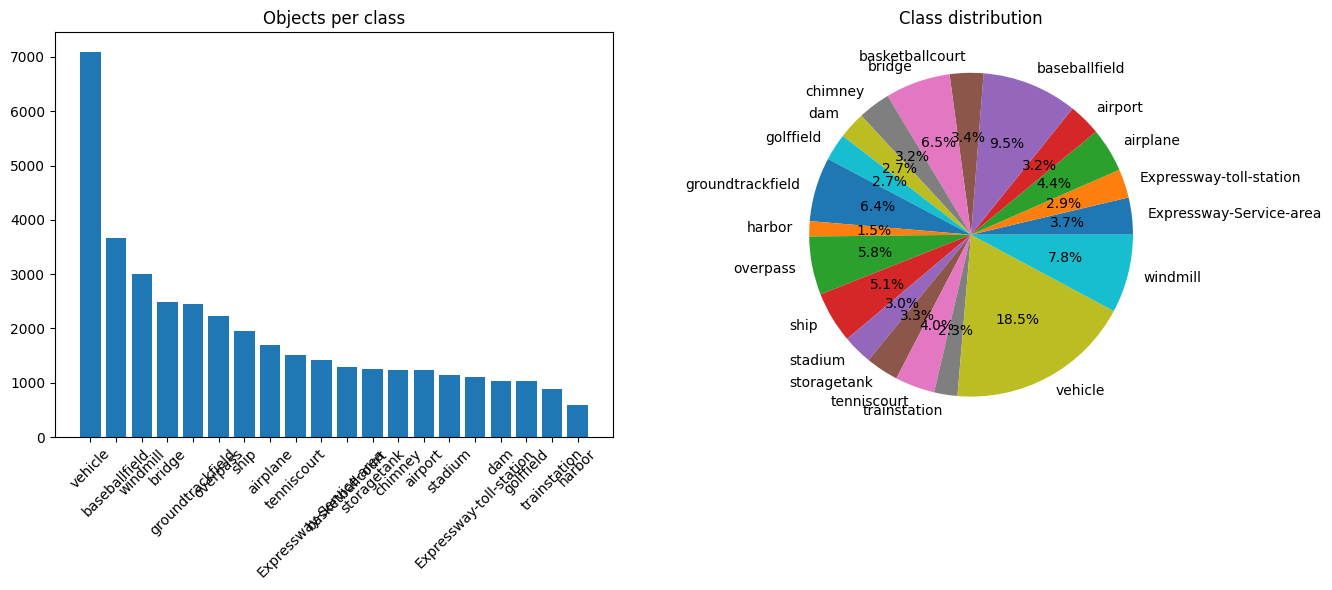

Plot saved to E:\Workplaces\CSE465 Project\runs\run_20260411_002521\plots\class_imbalance.png


In [9]:
idx             = np.argsort(-counts)
labels_sorted   = [class_names[i] for i in idx]
counts_sorted   = counts[idx]

min_pct_to_show = 1.0

big_idx    = np.where(percent_share >= min_pct_to_show)[0]
small_idx  = np.where(percent_share <  min_pct_to_show)[0]

pie_labels = [class_names[i] for i in big_idx]
pie_sizes  = percent_share[big_idx].tolist()

other_pct  = float(percent_share[small_idx].sum())
if other_pct > 0:
    pie_labels.append("Other")
    pie_sizes.append(other_pct)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].bar(labels_sorted, counts_sorted)
axes[0].set_title("Objects per class")
axes[0].tick_params(axis="x", rotation=45)

axes[1].pie(pie_sizes, labels=pie_labels, autopct="%1.1f%%")
axes[1].set_title("Class distribution")

plt.tight_layout()

# Save to disk AND show inline in the notebook
imbalance_plot = os.path.join(PLOTS_DIR, 'class_imbalance.png')
plt.savefig(imbalance_plot, dpi=150, bbox_inches='tight')
plt.show()
print(f'Plot saved to {imbalance_plot}')

## Class Definitions & Label Mapping

In [10]:
CLASSES = [
    'Expressway-Service-area', 'Expressway-toll-station', 'airplane',
    'airport', 'baseballfield', 'basketballcourt', 'bridge', 'chimney',
    'dam', 'golffield', 'groundtrackfield', 'harbor', 'overpass', 'ship',
    'stadium', 'storagetank', 'tenniscourt', 'trainstation', 'vehicle',
    'windmill'
]

# Background = 0, object classes = 1-20
ALL_LABELS = ['background'] + CLASSES
NUM_LABELS = len(ALL_LABELS)   # 21
label2id   = {name: idx for idx, name in enumerate(ALL_LABELS)}
id2label   = {idx: name for idx, name in enumerate(ALL_LABELS)}

CLASS_COUNTS = [
    1417, 1102, 1688, 1241, 3658, 1287, 2486, 1243,
    1037, 1032, 2455,  583, 2234, 1960, 1138, 1255,
    1519,  891, 7098, 2996
]

print(f'Total labels (incl. background): {NUM_LABELS}')

Total labels (incl. background): 21


## Class Imbalance - Inverse-Frequency Loss Weights

In [11]:
def compute_class_weights(counts, bg_weight=0.1):
    arr   = np.array(counts, dtype=np.float64)
    total = arr.sum()
    n     = len(arr)
    w     = total / (n * arr)
    w     = w / w.mean()
    w     = np.concatenate([[bg_weight], w])
    return torch.tensor(w, dtype=torch.float32)


CLASS_WEIGHTS = compute_class_weights(CLASS_COUNTS)

print('Top-5 highest weights (rarest classes):')
pairs = sorted(zip(ALL_LABELS, CLASS_WEIGHTS.tolist()), key=lambda x: -x[1])
for name, w in pairs[:6]:
    print(f'  {name:<32s}  {w:.4f}')

Top-5 highest weights (rarest classes):
  harbor                            2.4136
  trainstation                      1.5793
  golffield                         1.3635
  dam                               1.3569
  Expressway-toll-station           1.2769
  stadium                           1.2365


## Annotation Parser

In [12]:
def parse_xml_to_mask(xml_path: str, img_h: int, img_w: int) -> np.ndarray:

    mask = np.zeros((img_h, img_w), dtype=np.uint8)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    objects = []
    for obj in root.findall('object'):
        name = obj.find('name').text.strip()
        if name not in label2id:
            continue
        bb   = obj.find('bndbox')
        xmin = max(0,     int(float(bb.find('xmin').text)))
        ymin = max(0,     int(float(bb.find('ymin').text)))
        xmax = min(img_w, int(float(bb.find('xmax').text)))
        ymax = min(img_h, int(float(bb.find('ymax').text)))
        area = (xmax - xmin) * (ymax - ymin)
        objects.append((area, xmin, ymin, xmax, ymax, label2id[name]))

    objects.sort(reverse=True, key=lambda x: x[0])
    for _, xmin, ymin, xmax, ymax, cls_idx in objects:
        mask[ymin:ymax, xmin:xmax] = cls_idx

    return mask


# Quick sanity check
sample_xmls = sorted(glob.glob(os.path.join(LABEL_DIR, '**', '*.xml'), recursive=True))
print(f'Found {len(sample_xmls)} XML files')
if sample_xmls:
    sx   = sample_xmls[0]
    imgp = os.path.join(IMAGE_DIR, Path(sx).stem + '.jpg')
    if os.path.exists(imgp):
        _img = cv2.imread(imgp)
        _h, _w = _img.shape[:2]
        _mask  = parse_xml_to_mask(sx, _h, _w)
        print(f'Sample mask unique classes: {[id2label[u] for u in np.unique(_mask)]}')

Found 17402 XML files
Sample mask unique classes: ['background', 'golffield']


## Train / Val / Test Split

In [13]:
def build_file_pairs(image_dir, label_dir):
    xml_paths = sorted(glob.glob(os.path.join(label_dir, '**', '*.xml'), recursive=True))
    pairs = []
    for xp in xml_paths:
        img_p = os.path.join(image_dir, Path(xp).stem + '.jpg')
        if os.path.exists(img_p):
            pairs.append((img_p, xp))
    return pairs


all_pairs = build_file_pairs(IMAGE_DIR, LABEL_DIR)
print(f'Valid (image, xml) pairs: {len(all_pairs)}')

random.shuffle(all_pairs)
n      = len(all_pairs)
n_val  = int(n * 0.15)
n_test = int(n * 0.15)

test_pairs  = all_pairs[:n_test]
val_pairs   = all_pairs[n_test : n_test + n_val]
train_pairs = all_pairs[n_test + n_val :]

print(f'Train: {len(train_pairs)}  Val: {len(val_pairs)}  Test: {len(test_pairs)}')

Valid (image, xml) pairs: 17402
Train: 12182  Val: 2610  Test: 2610


## Data Augmentation Pipelines

In [14]:
IMG_SIZE = 480

train_transforms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomResizedCrop(
        size=(IMG_SIZE, IMG_SIZE), scale=(0.6, 1.0), ratio=(0.8, 1.2), p=0.4
    ),
    A.Perspective(scale=(0.02, 0.06), p=0.3),
    A.GridDistortion(num_steps=5, distort_limit=0.15, p=0.2),
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.6),
    A.CLAHE(clip_limit=4.0, p=0.3),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=20, p=0.4),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.Sharpen(alpha=(0.1, 0.4), lightness=(0.8, 1.2), p=0.2),
    A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_limit=(1, 2), shadow_dimension=5, p=0.2),
    A.GaussNoise(std_range=(0.01, 0.05), p=0.2),
    A.CoarseDropout(num_holes_range=(1, 4), hole_height_range=(0.05, 0.15),
                    hole_width_range=(0.05, 0.15), p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

val_transforms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

print(f'Image size: {IMG_SIZE}×{IMG_SIZE}  |  Transforms ready.')

Image size: 480×480  |  Transforms ready.


##  Dataset Class

In [15]:
class RRSISDataset(Dataset):
    def __init__(self, pairs, transforms=None):
        self.pairs      = pairs
        self.transforms = transforms

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, xml_path = self.pairs[idx]
        img = cv2.imread(img_path)
        if img is None:
            raise FileNotFoundError(f'Image not found: {img_path}')
        img  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        mask = parse_xml_to_mask(xml_path, h, w)

        if self.transforms:
            out  = self.transforms(image=img, mask=mask)
            img  = out['image']
            mask = out['mask']

        if not isinstance(mask, torch.Tensor):
            mask = torch.from_numpy(mask)
        return {'pixel_values': img, 'labels': mask.long()}

    def get_dominant_class(self, idx):
        img_path, xml_path = self.pairs[idx]
        img  = cv2.imread(img_path)
        h, w = img.shape[:2]
        mask = parse_xml_to_mask(xml_path, h, w)
        fg   = mask[mask > 0]
        return int(Counter(fg.tolist()).most_common(1)[0][0]) if len(fg) else 0


train_ds = RRSISDataset(train_pairs, transforms=train_transforms)
val_ds   = RRSISDataset(val_pairs,   transforms=val_transforms)
test_ds  = RRSISDataset(test_pairs,  transforms=val_transforms)

print(f'Train: {len(train_ds)}  Val: {len(val_ds)}  Test: {len(test_ds)}')

Train: 12182  Val: 2610  Test: 2610


## Data-Loaders

In [16]:
BATCH_SIZE  = 6
NUM_WORKERS = 0

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=False,
    drop_last=True,
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=False,
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=False,
)

print(f'Batch size    : {BATCH_SIZE}')
print(f'Train batches : {len(train_loader)}')
print(f'Val   batches : {len(val_loader)}')
print(f'Test  batches : {len(test_loader)}')


Batch size    : 6
Train batches : 2030
Val   batches : 435
Test  batches : 435


## Build SegFormer-B2 Model

In [17]:
def build_segformer(num_labels=NUM_LABELS,
                    pretrained='nvidia/mit-b2'):

    _id2label = {idx: name for idx, name in enumerate(ALL_LABELS)}
    _label2id = {name: idx for idx, name in enumerate(ALL_LABELS)}

    return SegformerForSemanticSegmentation.from_pretrained(
        pretrained,
        num_labels=num_labels,
        id2label=_id2label,
        label2id=_label2id,
        ignore_mismatched_sizes=True,
    )


model = build_segformer().to(DEVICE)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters      : {total_params:,}')
print(f'Trainable parameters  : {trainable_params:,}')

Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

Total parameters      : 27,362,773
Trainable parameters  : 27,362,773


## Model Size on Disk

In [18]:
import tempfile

def get_model_size_mb(model):
    with tempfile.NamedTemporaryFile(suffix='.pt', delete=False) as tmp:
        torch.save(model.state_dict(), tmp.name)
        size_mb = os.path.getsize(tmp.name) / (1024 ** 2)
    os.unlink(tmp.name)
    return size_mb


model_size_mb = get_model_size_mb(model)
print(f'Model size on disk    : {model_size_mb:.1f} MB')
print(f'Total parameters      : {total_params:,}')
print(f'Trainable parameters  : {trainable_params:,}')

Model size on disk    : 104.5 MB
Total parameters      : 27,362,773
Trainable parameters  : 27,362,773


## Loss Function - Weighted Focal + Dice

In [19]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, ignore_index=-100):
        super().__init__()
        self.alpha = alpha; self.gamma = gamma; self.ignore_index = ignore_index

    def forward(self, logits, targets):
        alpha = self.alpha.to(logits.device) if self.alpha is not None else None
        ce    = F.cross_entropy(logits, targets, weight=alpha,
                                ignore_index=self.ignore_index, reduction='none')
        with torch.no_grad():
            pt = torch.exp(-ce)
        focal = (1 - pt) ** self.gamma * ce
        return focal[targets != self.ignore_index].mean()


class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0, ignore_index=-100):
        super().__init__()
        self.smooth = smooth; self.ignore_index = ignore_index

    def forward(self, logits, targets):
        B, C, H, W = logits.shape
        probs      = logits.softmax(dim=1)
        valid      = (targets != self.ignore_index)
        t          = targets.clone(); t[~valid] = 0
        t_oh       = F.one_hot(t, C).permute(0, 3, 1, 2).float()
        vm         = valid.unsqueeze(1).float()
        inter      = (probs * vm * t_oh * vm).sum(dim=(0, 2, 3))
        union      = (probs * vm).sum(dim=(0, 2, 3)) + (t_oh * vm).sum(dim=(0, 2, 3))
        return 1.0 - ((2 * inter + self.smooth) / (union + self.smooth)).mean()


class CombinedLoss(nn.Module):
    def __init__(self, class_weights, dice_weight=0.5, gamma=2.0):
        super().__init__()
        self.focal       = FocalLoss(alpha=class_weights, gamma=gamma)
        self.dice        = DiceLoss()
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        return self.focal(logits, targets) + self.dice_weight * self.dice(logits, targets)


print('Loss: Weighted Focal + Dice ready.')

Loss: Weighted Focal + Dice ready.


## Comprehensive Metrics

In [20]:
class SegMetrics:

    def __init__(self, num_classes, ignore_index=-100):
        self.K            = num_classes
        self.ignore_index = ignore_index
        self.reset()

    def reset(self):
        self.cm = torch.zeros(self.K, self.K, dtype=torch.int64)

    @torch.no_grad()
    def update_fast(self, logits, targets):
        """Update confusion matrix only — no array accumulation."""
        if logits.shape[-2:] != targets.shape[-2:]:
            logits = F.interpolate(logits.float(), size=targets.shape[-2:],
                                   mode='bilinear', align_corners=False)
        preds   = logits.argmax(dim=1).cpu()
        targets = targets.cpu()
        valid   = (targets != self.ignore_index)
        p_flat  = preds[valid].numpy().astype(np.int32)
        t_flat  = targets[valid].numpy().astype(np.int32)
        combined = self.K * t_flat + p_flat
        counts   = np.bincount(combined, minlength=self.K ** 2)
        self.cm += torch.tensor(counts.reshape(self.K, self.K), dtype=torch.int64)

    def compute_fast(self):
        """
        Compute all metrics from confusion matrix.
        Precision / Recall / F1 are derived per-class from TP/FP/FN
        then macro-averaged — mathematically identical to sklearn macro
        but 1000x faster since no pixel arrays are needed.
        """
        cm  = self.cm.float()
        tp  = torch.diag(cm)
        fp  = cm.sum(dim=0) - tp
        fn  = cm.sum(dim=1) - tp

        # Only average over classes that appear in ground truth
        present = cm.sum(dim=1) > 0

        iou_per  = tp / (tp + fp + fn + 1e-6)
        dice_per = 2 * tp / (2 * tp + fp + fn + 1e-6)
        prec_per = tp / (tp + fp + 1e-6)
        rec_per  = tp / (tp + fn + 1e-6)
        f1_per   = 2 * prec_per * rec_per / (prec_per + rec_per + 1e-6)

        miou      = iou_per[present].mean().item()
        oiou      = (tp.sum() / (tp.sum() + fp.sum() + fn.sum() + 1e-6)).item()
        mdice     = dice_per[present].mean().item()
        pixel_acc = (tp.sum() / (cm.sum() + 1e-6)).item()
        precision = prec_per[present].mean().item()
        recall    = rec_per[present].mean().item()
        f1        = f1_per[present].mean().item()

        return {
            'pixel_acc'    : pixel_acc,
            'precision'    : precision,
            'recall'       : recall,
            'f1'           : f1,
            'mIoU'         : miou,
            'oIoU'         : oiou,
            'Dice'         : mdice,
            'iou_per_class': iou_per.tolist(),
        }

    def compute_confusion_matrix(self):
        return self.cm.numpy()


print('SegMetrics (fast) ready.')


SegMetrics (fast) ready.


## Early Stopping

In [21]:
class EarlyStopping:

    def __init__(self, patience=7, min_delta=0.001, verbose=True):
        self.patience   = patience
        self.min_delta  = min_delta
        self.verbose    = verbose
        self.best_score = None
        self.counter    = 0
        self.best_state = None
        self.triggered  = False

    def step(self, score: float, model: nn.Module) -> bool:
        import copy
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score = score
            self.counter    = 0
            self.best_state = copy.deepcopy(
                {k: v.cpu() for k, v in model.state_dict().items()}
            )
            if self.verbose:
                print(f'  [ES] New best: {score:.4f}  (counter reset)')
        else:
            self.counter += 1
            if self.verbose:
                print(f'  [ES] No improvement. Counter: {self.counter}/{self.patience}')
            if self.counter >= self.patience:
                self.triggered = True
                return True
        return False

    def restore(self, model: nn.Module):
        if self.best_state is not None:
            model.load_state_dict(
                {k: v.to(next(model.parameters()).device)
                 for k, v in self.best_state.items()}
            )
            print(f'  [ES] Best weights restored (best mIoU={self.best_score:.4f})')


print('EarlyStopping ready.')

EarlyStopping ready.


## Train / Evaluate Functions

In [22]:
def train_one_epoch(model, loader, criterion, optimizer,
                    onecycle_scheduler, scaler, device):
    model.train()
    metrics    = SegMetrics(NUM_LABELS)
    total_loss = 0.0

    for batch in loader:
        imgs    = batch['pixel_values'].to(device)
        targets = batch['labels'].to(device)

        optimizer.zero_grad(set_to_none=True)

        with autocast('cuda'):
            outputs = model(pixel_values=imgs)
            logits  = F.interpolate(
                outputs.logits.float(), size=targets.shape[-2:],
                mode='bilinear', align_corners=False
            )
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        onecycle_scheduler.step()   # OneCycleLR must step every batch

        total_loss += loss.item()
        metrics.update_fast(logits.detach(), targets)   # fast — no sklearn

    stats         = metrics.compute_fast()              # fast — no sklearn
    stats['loss'] = total_loss / len(loader)
    return stats


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    metrics    = SegMetrics(NUM_LABELS)
    total_loss = 0.0

    for batch in loader:
        imgs    = batch['pixel_values'].to(device)
        targets = batch['labels'].to(device)

        with autocast('cuda'):
            outputs = model(pixel_values=imgs)
            logits  = F.interpolate(
                outputs.logits.float(), size=targets.shape[-2:],
                mode='bilinear', align_corners=False
            )
            loss = criterion(logits, targets)

        total_loss += loss.item()
        metrics.update_fast(logits, targets)            # fast — no sklearn

    stats         = metrics.compute_fast()              # fast — no sklearn
    stats['loss'] = total_loss / len(loader)
    stats['_cm']  = metrics.compute_confusion_matrix()
    return stats


print('train_one_epoch() and evaluate() defined.')


train_one_epoch() and evaluate() defined.


## Training Configuration

In [23]:
best = {
    "lr"          : 6e-5,
    "weight_decay": 1e-4,
    "dice_weight" : 0.5,
    "focal_gamma" : 2.0,
}

LR           = best["lr"]
WEIGHT_DECAY = best["weight_decay"]
DICE_WEIGHT  = best["dice_weight"]
FOCAL_GAMMA  = best["focal_gamma"]
NUM_EPOCHS   = 30
ES_PATIENCE  = 7
SAVE_EVERY_N = 5

model = build_segformer().to(DEVICE)

bb_params   = [p for n, p in model.named_parameters() if "decode_head" not in n]
head_params = [p for n, p in model.named_parameters() if "decode_head" in n]

optimizer = torch.optim.AdamW(
    [{"params": bb_params,   "lr": LR * 0.1},
     {"params": head_params, "lr": LR}],
    weight_decay=WEIGHT_DECAY
)

total_steps  = len(train_loader) * NUM_EPOCHS
onecycle_sch = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=[LR * 0.1, LR],
    total_steps=total_steps, pct_start=0.1,
    div_factor=25, final_div_factor=1e4,
)

plateau_sch = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3, min_lr=1e-7
)

criterion  = CombinedLoss(CLASS_WEIGHTS, dice_weight=DICE_WEIGHT, gamma=FOCAL_GAMMA)
scaler     = GradScaler("cuda")
early_stop = EarlyStopping(patience=ES_PATIENCE, min_delta=0.001, verbose=True)

print(f"Config:")
print(f"  GPU             : RTX 4050 (6 GB VRAM)")
print(f"  IMG_SIZE        : {IMG_SIZE}x{IMG_SIZE}")
print(f"  BATCH_SIZE      : {BATCH_SIZE}")
print(f"  NUM_WORKERS     : {NUM_WORKERS}")
print(f"  Backbone LR     : {LR * 0.1:.2e}")
print(f"  Head LR         : {LR:.2e}")
print(f"  Weight decay    : {WEIGHT_DECAY:.2e}")
print(f"  Dice weight     : {DICE_WEIGHT:.2f}")
print(f"  Focal gamma     : {FOCAL_GAMMA:.2f}")
print(f"  Max epochs      : {NUM_EPOCHS}")
print(f"  Early stopping  : patience={ES_PATIENCE}")
print(f"  Save every N    : {SAVE_EVERY_N} epochs")
print(f"  Output dir      : {OUTPUT_DIR}")


Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

Config:
  GPU             : RTX 4050 (6 GB VRAM)
  IMG_SIZE        : 480x480
  BATCH_SIZE      : 6
  NUM_WORKERS     : 0
  Backbone LR     : 6.00e-06
  Head LR         : 6.00e-05
  Weight decay    : 1.00e-04
  Dice weight     : 0.50
  Focal gamma     : 2.00
  Max epochs      : 30
  Early stopping  : patience=7
  Save every N    : 5 epochs
  Output dir      : E:\Workplaces\CSE465 Project\runs\run_20260411_002521


## Training Loop

In [ ]:
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

print('GPU ready. Starting training...')
print(f'VRAM available: {torch.cuda.get_device_properties(0).total_memory / 1e6:.0f} MB')

history = {
    'train_loss': [], 'val_loss': [],
    'train_acc':  [], 'val_acc':  [],
    'train_miou': [], 'val_miou': [],
    'train_f1':   [], 'val_f1':   [],
    'epoch_time': [],
    'lr_backbone': [], 'lr_head': []
}

total_train_start = time.time()
best_vram_mb      = 0

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    train_stats = train_one_epoch(
        model, train_loader, criterion, optimizer, onecycle_sch, scaler, DEVICE
    )
    val_stats   = evaluate(model, val_loader, criterion, DEVICE)
    plateau_sch.step(val_stats['mIoU'])
    epoch_time  = time.time() - epoch_start

    vram_mb = torch.cuda.max_memory_allocated() / 1e6
    if vram_mb > best_vram_mb:
        best_vram_mb = vram_mb
    torch.cuda.reset_peak_memory_stats()

    history['train_loss'].append(train_stats['loss'])
    history['val_loss'].append(val_stats['loss'])
    history['train_acc'].append(train_stats['pixel_acc'])
    history['val_acc'].append(val_stats['pixel_acc'])
    history['train_miou'].append(train_stats['mIoU'])
    history['val_miou'].append(val_stats['mIoU'])
    history['train_f1'].append(train_stats['f1'])
    history['val_f1'].append(val_stats['f1'])
    history['epoch_time'].append(epoch_time)
    history['lr_backbone'].append(optimizer.param_groups[0]['lr'])
    history['lr_head'].append(optimizer.param_groups[1]['lr'])

    print(
        f'Epoch {epoch:3d}/{NUM_EPOCHS} | '
        f'loss {train_stats["loss"]:.4f}/{val_stats["loss"]:.4f} | '
        f'acc {train_stats["pixel_acc"]:.4f}/{val_stats["pixel_acc"]:.4f} | '
        f'mIoU {train_stats["mIoU"]:.4f}/{val_stats["mIoU"]:.4f} | '
        f'F1 {train_stats["f1"]:.4f}/{val_stats["f1"]:.4f} | '
        f'{epoch_time:.0f}s | VRAM {vram_mb:.0f}MB'
    )

    # Always save last checkpoint — safe recovery if training is interrupted
    torch.save({
        'epoch':        epoch,
        'model_state':  model.state_dict(),
        'optim_state':  optimizer.state_dict(),
        'scaler_state': scaler.state_dict(),
        'val_miou':     val_stats['mIoU'],
        'hparams':      best,
        'history':      history,
    }, LAST_CKPT_PATH)

    # Save best checkpoint when val mIoU improves
    if early_stop.best_score is None or val_stats['mIoU'] > early_stop.best_score:
        torch.save({
            'epoch':        epoch,
            'model_state':  model.state_dict(),
            'optim_state':  optimizer.state_dict(),
            'scaler_state': scaler.state_dict(),
            'val_miou':     val_stats['mIoU'],
            'hparams':      best,
            'history':      history,
        }, BEST_CKPT_PATH)
        print(f'  -> Best checkpoint saved (val mIoU={val_stats["mIoU"]:.4f})')

    # Periodic checkpoint every SAVE_EVERY_N epochs
    if SAVE_EVERY_N > 0 and epoch % SAVE_EVERY_N == 0:
        periodic_path = os.path.join(WEIGHTS_DIR, f'epoch_{epoch:03d}.pt')
        torch.save({
            'epoch':       epoch,
            'model_state': model.state_dict(),
            'val_miou':    val_stats['mIoU'],
        }, periodic_path)
        print(f'  -> Periodic checkpoint saved: {periodic_path}')

    # Early stopping
    if early_stop.step(val_stats['mIoU'], model):
        print(f'\nEarly stopping triggered at epoch {epoch}.')
        break

early_stop.restore(model)

total_train_time = time.time() - total_train_start
avg_epoch_time   = np.mean(history['epoch_time'])

print(f'\nTraining complete.')
print(f'  Total training time  : {total_train_time / 60:.1f} min')
print(f'  Average time / epoch : {avg_epoch_time:.1f} s')
print(f'  Best val mIoU        : {early_stop.best_score:.4f}')
print(f'  Peak VRAM usage      : {best_vram_mb:.0f} MB / 6400 MB')
print(f'  Weights saved to     : {WEIGHTS_DIR}')

## Training Curves

In [ ]:
def plot_training_curves(history, save_path=None):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle('Training Dashboard — RRSIS-D SegFormer-B2 (480×480)',
                 fontsize=14, fontweight='bold', y=1.01)

    ax = axes[0, 0]
    ax.plot(epochs, history['train_loss'], 'b-o', ms=3, label='Train')
    ax.plot(epochs, history['val_loss'],   'r-o', ms=3, label='Val')
    ax.set_title('Loss (Focal + Dice)'); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[0, 1]
    ax.plot(epochs, [v * 100 for v in history['train_acc']], 'b-o', ms=3, label='Train')
    ax.plot(epochs, [v * 100 for v in history['val_acc']],   'r-o', ms=3, label='Val')
    ax.set_title('Pixel Accuracy (%)'); ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy (%)')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[0, 2]
    ax.plot(epochs, [v * 100 for v in history['train_miou']], 'b-o', ms=3, label='Train')
    ax.plot(epochs, [v * 100 for v in history['val_miou']],   'r-o', ms=3, label='Val')
    ax.set_title('Mean IoU (%)'); ax.set_xlabel('Epoch'); ax.set_ylabel('mIoU (%)')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1, 0]
    ax.plot(epochs, [v * 100 for v in history['train_f1']], 'b-o', ms=3, label='Train')
    ax.plot(epochs, [v * 100 for v in history['val_f1']],   'r-o', ms=3, label='Val')
    ax.set_title('F1 Score — macro (%)'); ax.set_xlabel('Epoch'); ax.set_ylabel('F1 (%)')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1, 1]
    ax.semilogy(epochs, history['lr_backbone'], 'g-', label='Backbone LR')
    ax.semilogy(epochs, history['lr_head'],     'm-', label='Head LR')
    ax.set_title('Learning Rate Schedule'); ax.set_xlabel('Epoch'); ax.set_ylabel('LR (log)')
    ax.legend(); ax.grid(alpha=0.3, which='both')

    ax = axes[1, 2]
    ax.bar(epochs, history['epoch_time'], color='steelblue', alpha=0.7)
    ax.axhline(np.mean(history['epoch_time']), color='red', linestyle='--',
               label=f'Mean={np.mean(history["epoch_time"]):.0f}s')
    ax.set_title('Training Time per Epoch'); ax.set_xlabel('Epoch'); ax.set_ylabel('Seconds')
    ax.legend(); ax.grid(alpha=0.3, axis='y')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'Training curves saved to {save_path}')
    plt.show()


plot_training_curves(
    history,
    save_path=os.path.join(PLOTS_DIR, 'training_curves.png')
)

## Test Set Evaluation - All Metrics

In [ ]:
ckpt = torch.load(BEST_CKPT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Loaded best checkpoint from epoch {ckpt["epoch"]}  '
      f'(val mIoU={ckpt["val_miou"]:.4f})\n')

test_stats = evaluate(model, test_loader, criterion, DEVICE)

print('=' * 55)
print(' TEST SET RESULTS')
print('=' * 55)
print(f'  Loss            : {test_stats["loss"]:.4f}')
print(f'  Pixel Accuracy  : {test_stats["pixel_acc"] * 100:.2f}%')
print(f'  Precision (mac) : {test_stats["precision"] * 100:.2f}%')
print(f'  Recall (macro)  : {test_stats["recall"] * 100:.2f}%')
print(f'  F1 (macro)      : {test_stats["f1"] * 100:.2f}%')
print(f'  mIoU            : {test_stats["mIoU"] * 100:.2f}%')
print(f'  oIoU            : {test_stats["oIoU"] * 100:.2f}%')
print(f'  Dice (mean)     : {test_stats["Dice"] * 100:.2f}%')
print('=' * 55)
print(f'\nModel info:')
print(f'  Total params     : {total_params:,}')
print(f'  Trainable params : {trainable_params:,}')
print(f'  Model size       : {model_size_mb:.1f} MB')
print(f'  Total train time : {total_train_time / 60:.1f} min')
print(f'  Avg epoch time   : {avg_epoch_time:.1f} s')
print(f'  Epochs run       : {len(history["train_loss"])}')
print('\nPer-class IoU:')
print(f'  {"ID":<4} {"Class":<32} {"IoU":>6}')
print('  ' + '-' * 46)
for idx in range(NUM_LABELS):
    print(f'  {idx:<4} {id2label[idx]:<32} {test_stats["iou_per_class"][idx] * 100:>5.2f}%')

## Confusion Matrix

In [ ]:
def plot_confusion_matrix(cm, labels, save_path=None, normalise=True):
    if normalise:
        row_sums = cm.sum(axis=1, keepdims=True)
        row_sums = np.where(row_sums == 0, 1, row_sums)
        cm_plot  = cm.astype(float) / row_sums
        fmt      = '.2f'
        title    = 'Confusion Matrix (row-normalised)'
    else:
        cm_plot  = cm
        fmt      = 'd'
        title    = 'Confusion Matrix (raw counts)'

    short_labels = [l[:12] for l in labels]
    fig, ax = plt.subplots(figsize=(18, 15))
    sns.heatmap(cm_plot, annot=True, fmt=fmt, cmap='Blues',
                xticklabels=short_labels, yticklabels=short_labels,
                linewidths=0.4, linecolor='lightgrey', ax=ax)
    ax.set_xlabel('Predicted class', fontsize=11)
    ax.set_ylabel('True class',      fontsize=11)
    ax.set_title(title,              fontsize=13, fontweight='bold')
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(rotation=0,              fontsize=8)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'Confusion matrix saved to {save_path}')
    plt.show()


plot_confusion_matrix(
    test_stats['_cm'], ALL_LABELS,
    save_path=os.path.join(PLOTS_DIR, 'confusion_matrix.png'), normalise=True
)
plot_confusion_matrix(
    test_stats['_cm'], ALL_LABELS,
    save_path=os.path.join(PLOTS_DIR, 'confusion_matrix_raw.png'), normalise=False
)

## Per-Class IoU Bar Chart

In [ ]:
def plot_per_class_iou(iou_list, labels, save_path=None):
    values = [iou_list[i] * 100 for i in range(len(labels))]
    pairs  = sorted(zip(labels, values), key=lambda x: x[1], reverse=True)
    names, vals = zip(*pairs)
    colours = ['#2196F3' if v >= 50 else '#FF9800' if v >= 25 else '#F44336' for v in vals]
    fig, ax = plt.subplots(figsize=(10, 9))
    bars = ax.barh(range(len(names)), vals, color=colours, edgecolor='white')
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=9)
    ax.set_xlabel('IoU (%)')
    ax.set_title('Per-class IoU on Test Set', fontsize=12, fontweight='bold')
    ax.axvline(np.mean(vals), color='black', linestyle='--',
               label=f'Mean mIoU={np.mean(vals):.1f}%')
    ax.legend(fontsize=9)
    ax.grid(axis='x', alpha=0.3)
    for bar, v in zip(bars, vals):
        ax.text(v + 0.5, bar.get_y() + bar.get_height() / 2,
                f'{v:.1f}%', va='center', fontsize=8)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'Per-class IoU chart saved to {save_path}')
    plt.show()


plot_per_class_iou(
    test_stats['iou_per_class'], ALL_LABELS,
    save_path=os.path.join(PLOTS_DIR, 'per_class_iou.png')
)

## Full Results Summary & Save to runs/ Folder

In [ ]:
# Print summary table
rows = [
    ('Pixel Accuracy',     f"{test_stats['pixel_acc'] * 100:.2f}%"),
    ('Precision (macro)',  f"{test_stats['precision'] * 100:.2f}%"),
    ('Recall (macro)',     f"{test_stats['recall'] * 100:.2f}%"),
    ('F1 Score (macro)',   f"{test_stats['f1'] * 100:.2f}%"),
    ('mIoU',               f"{test_stats['mIoU'] * 100:.2f}%"),
    ('oIoU',               f"{test_stats['oIoU'] * 100:.2f}%"),
    ('Dice (mean)',        f"{test_stats['Dice'] * 100:.2f}%"),
    ('Test Loss',          f"{test_stats['loss']:.4f}"),
    ('---',                '---'),
    ('Total Parameters',   f'{total_params:,}'),
    ('Trainable Params',   f'{trainable_params:,}'),
    ('Model Size',         f'{model_size_mb:.1f} MB'),
    ('Total Train Time',   f'{total_train_time / 60:.1f} min'),
    ('Avg Epoch Time',     f'{avg_epoch_time:.1f} s'),
    ('Epochs Run / Max',   f'{len(history["train_loss"])} / {NUM_EPOCHS}'),
    ('Image Size',         f'{IMG_SIZE}×{IMG_SIZE}'),
    ('GPU',                'RTX 4050 6GB'),
    ('Run Folder',         RUN_NAME),
]
print(f'{"Metric":<28}  {"Value"}')
print('-' * 50)
for m, v in rows:
    if m == '---':
        print('-' * 50)
    else:
        print(f'{m:<28}  {v}')

# Save full JSON results to logs/
json_summary = {
    'run_name'     : RUN_NAME,
    'run_folder'   : OUTPUT_DIR,
    'test_metrics' : {k: v for k, v in test_stats.items() if k != '_cm'},
    'confusion_matrix': test_stats['_cm'].tolist(),
    'model_info'   : {
        'total_params'     : total_params,
        'trainable_params' : trainable_params,
        'model_size_mb'    : model_size_mb,
        'img_size'         : IMG_SIZE,
        'backbone'         : 'nvidia/mit-b2',
    },
    'training_info': {
        'total_train_time_s': total_train_time,
        'avg_epoch_time_s'  : avg_epoch_time,
        'epochs_run'        : len(history['train_loss']),
        'early_stopped'     : early_stop.triggered,
        'batch_size'        : BATCH_SIZE,
        'num_workers'       : NUM_WORKERS,
    },
    'hparams': best,
    'history': history,
}

with open(SUMMARY_FILE, 'w') as f:
    json.dump(json_summary, f, indent=2)
print(f'\nFull results saved to {SUMMARY_FILE}')

# Also save the HuggingFace model to weights/ for easy reloading
hf_save_dir = os.path.join(WEIGHTS_DIR, 'hf_model')
os.makedirs(hf_save_dir, exist_ok=True)
model.save_pretrained(hf_save_dir)
SegformerImageProcessor.from_pretrained('nvidia/mit-b2').save_pretrained(hf_save_dir)
print(f'HuggingFace model saved to {hf_save_dir}')
print(f'\nAll run outputs are in: {OUTPUT_DIR}')

## Qualitative Visualisation

In [ ]:
@torch.no_grad()
def visualise_predictions(model, dataset, n=4, device=DEVICE):
    model.eval()
    indices = random.sample(range(len(dataset)), n)
    fig, axes = plt.subplots(n, 3, figsize=(14, 4 * n))
    if n == 1:
        axes = axes[np.newaxis]

    for row, idx in enumerate(indices):
        sample    = dataset[idx]
        img_t     = sample['pixel_values'].unsqueeze(0).to(device)
        gt_mask   = sample['labels'].numpy()
        output    = model(pixel_values=img_t)
        logits    = F.interpolate(output.logits, size=gt_mask.shape,
                                  mode='bilinear', align_corners=False)
        pred_mask = logits.argmax(dim=1).squeeze().cpu().numpy()
        img_np    = denormalise(sample['pixel_values']).permute(1, 2, 0).numpy()
        px_acc    = np.mean(gt_mask == pred_mask)

        axes[row, 0].imshow(img_np)
        axes[row, 0].set_title('Image', fontsize=9); axes[row, 0].axis('off')
        axes[row, 1].imshow(gt_mask, cmap=CMAP, vmin=0, vmax=NUM_LABELS - 1)
        gt_cls = ', '.join(id2label[u][:8] for u in np.unique(gt_mask) if u > 0)[:40]
        axes[row, 1].set_title(f'GT: {gt_cls}', fontsize=7); axes[row, 1].axis('off')
        axes[row, 2].imshow(pred_mask, cmap=CMAP, vmin=0, vmax=NUM_LABELS - 1)
        axes[row, 2].set_title(f'Pred (px acc={px_acc:.2f})', fontsize=8)
        axes[row, 2].axis('off')

    patches = [mpatches.Patch(color=CMAP(i / NUM_LABELS), label=id2label[i])
               for i in range(NUM_LABELS)]
    fig.legend(handles=patches, loc='lower center', ncol=7,
               fontsize=7, bbox_to_anchor=(0.5, -0.02))
    plt.suptitle('Test set predictions', fontsize=12, fontweight='bold', y=1.01)
    plt.tight_layout()
    save_path = os.path.join(PLOTS_DIR, 'test_predictions.png')
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Predictions saved to {save_path}')


visualise_predictions(model, test_ds, n=4)

## Single Image Inference

In [ ]:
@torch.no_grad()
def predict_single(image_path: str, model, device=DEVICE, save_path=None):
    """
    Run segmentation on a single image and save the result.
    Since matplotlib is in Agg mode, set save_path to view the result.
    """
    model.eval()
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    t         = val_transforms(image=img)
    inp       = t['image'].unsqueeze(0).to(device)
    output    = model(pixel_values=inp)
    logits    = F.interpolate(output.logits, size=(h, w),
                              mode='bilinear', align_corners=False)
    pred_mask = logits.argmax(dim=1).squeeze().cpu().numpy()

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(img); axes[0].set_title('Input'); axes[0].axis('off')
    axes[1].imshow(pred_mask, cmap=CMAP, vmin=0, vmax=NUM_LABELS - 1)
    axes[1].set_title('Prediction'); axes[1].axis('off')
    unique  = np.unique(pred_mask)
    patches = [mpatches.Patch(color=CMAP(u / NUM_LABELS), label=id2label[u]) for u in unique]
    plt.legend(handles=patches, loc='lower right', fontsize=8)
    plt.tight_layout()

    out = save_path or os.path.join(PLOTS_DIR, 'inference_result.png')
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Result saved to {out}')
    return {'mask': pred_mask, 'classes': [id2label[u] for u in unique]}


